In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# df = pd.read_csv('logs/2025-07-24-09-58-47_inferences.csv')
# df = pd.read_csv('logs/2025-07-24-11-06-21_inferences.csv')
# df = pd.read_csv('logs/2025-07-24-11-27-59_inferences.csv')
df = pd.read_csv('logs/2025-07-29-18-14-19_inferences.csv') # "fixed" model, tested on entire dataset
df = pd.read_csv('logs/2025-07-29-18-18-94_inferences.csv') # "fixed" model, tested only on test dataset
df.describe()

,targets_100,preds_100,mae_100,mse_100,mre_100,targets_125,preds_125,mae_125,mse_125,mre_125,...,targets_3150,preds_3150,mae_3150,mse_3150,mre_3150,targets_4000,preds_4000,mae_4000,mse_4000,mre_4000
count,32825.000000,32825.000000,3.282500e+04,3.282500e+04,32825.000000,32825.000000,32825.000000,32825.000000,3.282500e+04,32825.000000,...,32825.000000,32825.000000,3.282500e+04,3.282500e+04,32825.000000,32825.000000,32825.000000,3.282500e+04,3.282500e+04,32825.000000
mean,0.732642,0.727483,1.523367e-02,4.294797e-04,2.084432,0.723184,0.717369,0.013450,3.200451e-04,1.861886,...,0.182637,0.202299,4.416181e-02,3.669996e-03,33.602352,0.174357,0.193817,4.478627e-02,3.784159e-03,37.833536
std,0.017481,0.020708,1.405066e-02,1.995350e-03,1.944614,0.017903,0.015406,0.011796,8.945894e-04,1.642206,...,0.082017,0.064908,4.147026e-02,8.923917e-03,48.381200,0.084637,0.068803,4.217112e-02,8.492488e-03,61.113228
min,0.616302,0.400683,1.788139e-07,3.197442e-14,0.000024,0.628035,0.579938,0.000001,2.046363e-12,0.000198,...,0.020281,-0.521892,9.238720e-07,8.535395e-13,0.000557,0.013658,-0.344147,5.215406e-08,2.720046e-15,0.000053
25%,0.726306,0.715110,5.674422e-03,3.219906e-05,0.774077,0.716494,0.708886,0.005304,2.813030e-05,0.734175,...,0.121550,0.160159,1.585136e-02,2.512657e-04,8.108765,0.111250,0.147903,1.611132e-02,2.595746e-04,8.710474
50%,0.735249,0.726973,1.206374e-02,1.455339e-04,1.646046,0.725626,0.717503,0.010889,1.185598e-04,1.503839,...,0.169228,0.196276,3.331193e-02,1.109685e-03,19.281050,0.160941,0.186473,3.361192e-02,1.129761e-03,20.652079
75%,0.742659,0.739325,2.090192e-02,4.368902e-04,2.845045,0.733254,0.725905,0.018281,3.341856e-04,2.517876,...,0.231034,0.239109,5.855939e-02,3.429202e-03,40.484969,0.223881,0.232558,5.899996e-02,3.480995e-03,43.245198
max,0.855422,1.247426,5.083006e-01,2.583695e-01,68.770513,0.862471,1.025810,0.306156,9.373167e-02,42.542193,...,0.600147,0.581093,6.705645e-01,4.496567e-01,1323.461899,0.593958,0.659572,4.405448e-01,1.940797e-01,1541.176442


In [35]:
frequencies = [100,125,160,200,250,315,400,500,630,800,1000,1250,1600,2000,2500,3150,4000]
frequencies_str = ['100','125','160','200','250','315','400','500','630','800','1000','1250','1600','2000','2500','3150','4000']
losses = ['mae', 'mse', 'mre']

## Comparing Predictions

In [36]:
pred = df[[f'preds_{freq}' for freq in frequencies]]
pred.describe()

,preds_100,preds_125,preds_160,preds_200,preds_250,preds_315,preds_400,preds_500,preds_630,preds_800,preds_1000,preds_1250,preds_1600,preds_2000,preds_2500,preds_3150,preds_4000
count,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000
mean,0.727483,0.717369,0.701616,0.687841,0.668731,0.653274,0.625368,0.530436,0.416679,0.395568,0.359531,0.315107,0.265268,0.217188,0.200852,0.202299,0.193817
std,0.020708,0.015406,0.017006,0.020736,0.020658,0.025739,0.035170,0.025592,0.025836,0.060183,0.079906,0.082897,0.069442,0.062639,0.060456,0.064908,0.068803
min,0.400683,0.579938,0.572278,0.359442,0.313497,0.206542,0.230949,0.267274,0.177711,-0.000966,-0.083938,-0.328454,-0.361594,-0.549828,-0.679032,-0.521892,-0.344147
25%,0.715110,0.708886,0.691514,0.675539,0.655906,0.637128,0.602781,0.513609,0.400031,0.350849,0.300128,0.258516,0.221242,0.176900,0.162360,0.160159,0.147903
50%,0.726973,0.717503,0.701643,0.688149,0.667855,0.652888,0.623807,0.529291,0.414903,0.387325,0.353552,0.315501,0.265806,0.213905,0.196655,0.196276,0.186473
75%,0.739325,0.725905,0.711383,0.700388,0.680829,0.668956,0.645768,0.545859,0.430673,0.430638,0.412258,0.371272,0.308944,0.253208,0.234603,0.239109,0.232558
max,1.247426,1.025810,1.103098,0.835677,0.814231,1.113234,1.448627,1.115235,0.644947,0.991495,0.682913,0.715226,0.810942,0.900623,0.939035,0.581093,0.659572


In [37]:
for freq in frequencies:
    print(f"Number of unique values for frequency {freq}: {pred[f'preds_{freq}'].nunique()}")

Number of unique values for frequency 100: 32333
Number of unique values for frequency 125: 32170
Number of unique values for frequency 160: 32263
Number of unique values for frequency 200: 32340
Number of unique values for frequency 250: 32281
Number of unique values for frequency 315: 32106
Number of unique values for frequency 400: 32548
Number of unique values for frequency 500: 32395
Number of unique values for frequency 630: 32460
Number of unique values for frequency 800: 32730
Number of unique values for frequency 1000: 32769
Number of unique values for frequency 1250: 32762
Number of unique values for frequency 1600: 32754
Number of unique values for frequency 2000: 32759
Number of unique values for frequency 2500: 32738
Number of unique values for frequency 3150: 32769
Number of unique values for frequency 4000: 32778


## Plotting Losses by Frequency

In [38]:
mean_mae_by_freq = np.zeros(len(frequencies))
mean_mse_by_freq = np.zeros(len(frequencies))
mean_mre_by_freq = np.zeros(len(frequencies))
for i, freq in enumerate(frequencies):
    mean_mae_by_freq[i] = df[f'mae_{freq}'].mean()
    mean_mse_by_freq[i] = df[f'mse_{freq}'].mean()
    mean_mre_by_freq[i] = df[f'mre_{freq}'].mean()

mean_mae = np.mean(mean_mae_by_freq)
mean_mse = np.mean(mean_mse_by_freq)
mean_mre = np.mean(mean_mre_by_freq)

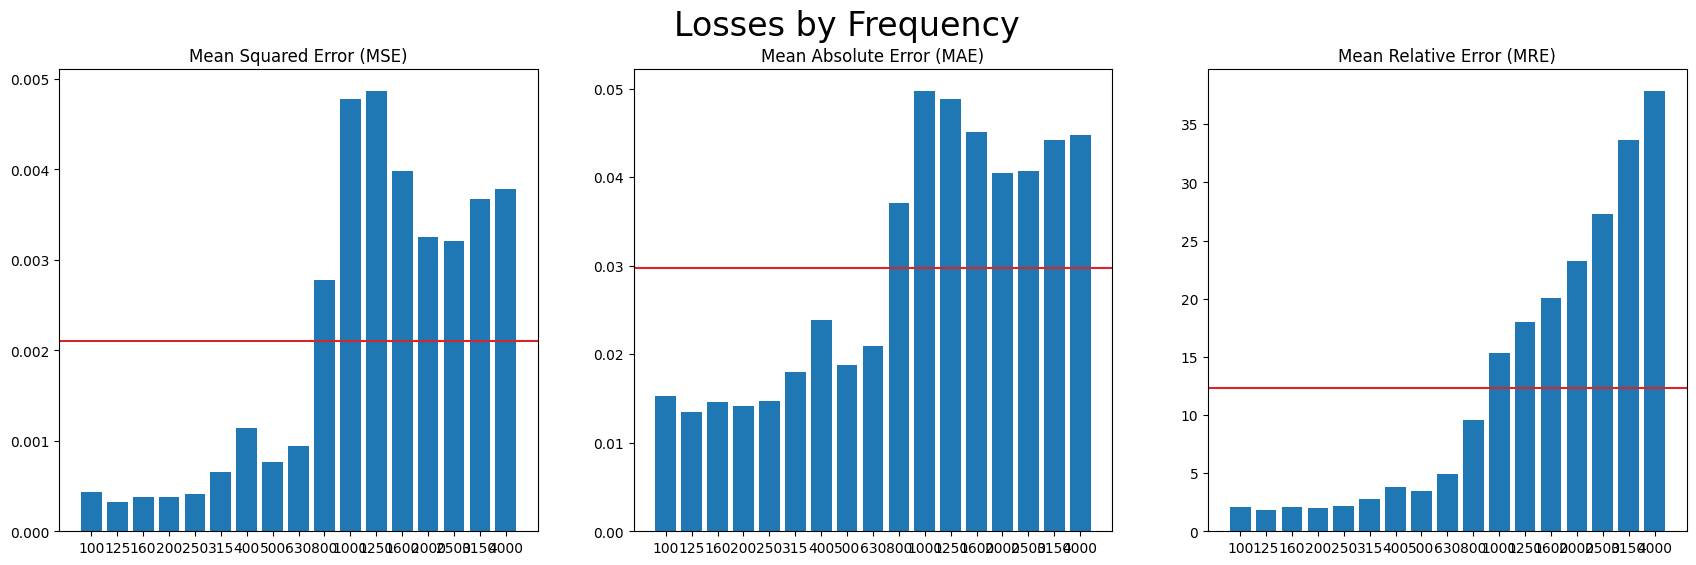

In [39]:
f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21,6))

f.suptitle('Losses by Frequency', fontsize=24)
ax1.bar(frequencies_str, mean_mse_by_freq)
ax1.set_title('Mean Squared Error (MSE)')
ax1.axhline(mean_mse, color='tab:red', label='Mean MSE')
ax2.bar(frequencies_str, mean_mae_by_freq)
ax2.set_title('Mean Absolute Error (MAE)')
ax2.axhline(mean_mae, color='tab:red', label='Mean MAE')
ax3.bar(frequencies_str, mean_mre_by_freq)
ax3.set_title('Mean Relative Error (MRE)')
ax3.axhline(mean_mre, color='tab:red', label='Mean MRE')

# plt.yticks([])

plt.show()

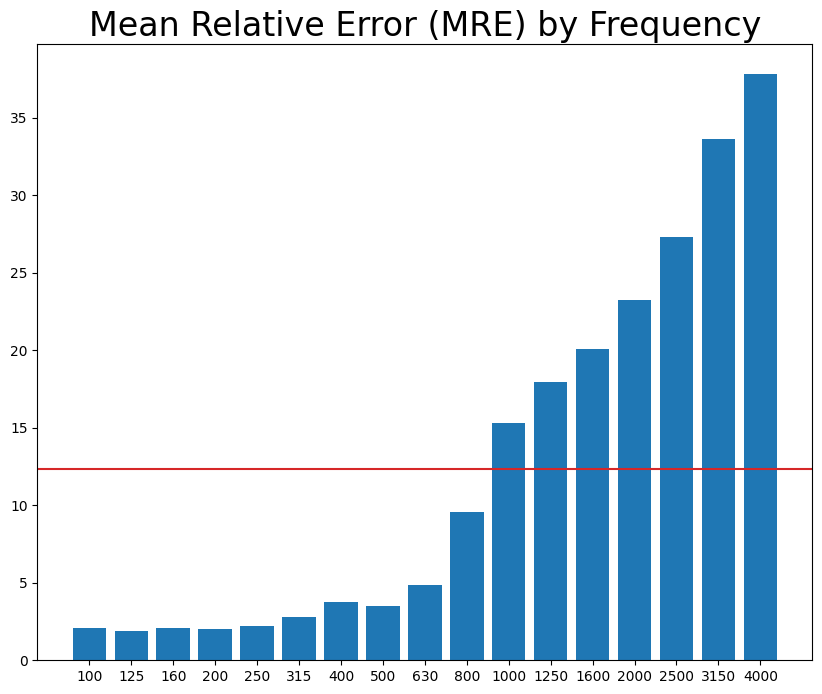

In [41]:
f, ax1 = plt.subplots(1, 1, figsize=(10,8))

ax1.bar(frequencies_str, mean_mre_by_freq)
ax1.set_title('Mean Relative Error (MRE) by Frequency', fontsize=24)
ax1.axhline(mean_mre, color='tab:red', label='Mean MRE')

# plt.yticks([])

plt.show()